# FINAL Stage 7 – Corrected Adversarial Attack Generation and Evaluation

**Research:** Unsupervised graph-based adversarial attack detection and severity estimation in Alzheimer’s MRI classification.

This is the consolidated, corrected Stage 7 notebook for the project repository. It regenerates FGSM, PGD and CW-L2 examples using the fixed Stage 4 CNN and the original Stage 3 train/validation/test split indices.

## Key correction in this final version

**Attacks are generated only on images that the clean Stage 4 CNN classifies correctly.** This is the appropriate denominator for measuring whether an attack causes a previously correct prediction to become incorrect.

Images already misclassified by the clean CNN are recorded separately and are not counted as attack successes. This corrects the evaluation issue identified in the earlier Stage 7 output.

## Protocol
- Fixed Stage 4 CNN; no retraining in this notebook.
- Same Stage 3 split indices; no new split is created.
- FGSM: L-infinity epsilon = 0.03.
- PGD: L-infinity epsilon = 0.03, alpha = 0.0075, 10 steps, random start.
- CW-L2: untargeted tanh-space L2 optimization, confidence = 0, learning rate = 0.01, 100 iterations, 3 binary-search steps, initial constant = 0.01.
- Attack success is counted only among samples correctly classified before the attack.
- Results are reported separately for train, validation and test.
- No attack result is forced to reach a target success rate. Failed attacks remain failed and are reported honestly.

**Important:** This is an image-level split. The CW implementation is a practical CW-L2-style implementation and its exact objective/settings should be described in the manuscript. Do not call it a specific library implementation.

## Step 1 – Environment setup

In [1]:
import os, json, zipfile, random, time, shutil, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if DEVICE.type == "cpu":
    print("WARNING: CW-L2 will be slow on CPU. Use Runtime > Change runtime type > T4 GPU if available.")

PyTorch: 2.11.0+cu130
Device: cuda


## Step 2 – Upload Stage 3 and Stage 4 output ZIP files

In [2]:
from google.colab import files
uploaded = files.upload()
print("Uploaded:", list(uploaded.keys()))

Saving Stage3_Preprocessing_Outputs.zip to Stage3_Preprocessing_Outputs.zip
Saving Stage4_CNN_Outputs.zip to Stage4_CNN_Outputs.zip
Uploaded: ['Stage3_Preprocessing_Outputs.zip', 'Stage4_CNN_Outputs.zip']


## Step 3 – Extract and list files

In [3]:
WORK = Path("/content/final_stage7_work")
S3 = WORK / "stage3"; S4 = WORK / "stage4"
S3.mkdir(parents=True, exist_ok=True); S4.mkdir(parents=True, exist_ok=True)

def safe_extract(zip_path, out_dir):
    with zipfile.ZipFile(zip_path, "r") as zf:
        for member in zf.infolist():
            target = (out_dir / member.filename).resolve()
            if not str(target).startswith(str(out_dir.resolve())):
                raise ValueError("Unsafe ZIP path detected.")
        zf.extractall(out_dir)

names = list(uploaded.keys())
z3 = next((n for n in names if "stage3" in n.lower()), None)
z4 = next((n for n in names if "stage4" in n.lower()), None)
if not z3 or not z4:
    raise FileNotFoundError("Upload both Stage3_Preprocessing_Outputs.zip and Stage4_CNN_Outputs.zip.")
safe_extract(z3, S3); safe_extract(z4, S4)

print("STAGE 3 CONTENTS")
for p in S3.rglob("*"):
    if p.is_file(): print(p.relative_to(S3), p.stat().st_size)
print("\nSTAGE 4 CONTENTS")
for p in S4.rglob("*"):
    if p.is_file(): print(p.relative_to(S4), p.stat().st_size)

STAGE 3 CONTENTS
class_distribution_by_split.csv 138
alzheimer_images_uint8.npz 59977882
preprocessing_config.json 781
split_manifest.csv 771838

STAGE 4 CONTENTS
stage4_config_and_metrics.json 997
cnn_test_confusion_matrix.csv 171
cnn_embedding_manifest.csv 802746
cnn_test_class_metrics.csv 265
cnn_embeddings_128d.npz 1087733
best_alzheimer_cnn.pth 5071269
cnn_training_history.csv 3703


## Step 4 – Identify Stage 3 image and label arrays

In [4]:
npz3 = list(S3.rglob("*.npz"))
if not npz3: raise FileNotFoundError("No NPZ file found in Stage 3 ZIP.")
image_candidates=[]; label_candidates=[]
for p in npz3:
    with np.load(p, allow_pickle=False) as z:
        for k in z.files:
            a=z[k]
            if a.ndim in (3,4) and a.shape[0]==6400 and a.shape[-2:]==(128,128):
                image_candidates.append((p,k,a.shape))
            if a.ndim==1 and a.shape[0]==6400:
                label_candidates.append((p,k,a.shape,str(a.dtype)))
print("Image candidates:", image_candidates)
print("Label candidates:", label_candidates)
if len(image_candidates)!=1 or len(label_candidates)!=1:
    raise RuntimeError("Could not uniquely identify image and label arrays. Share this cell's output for a loader adjustment.")
img_file,img_key,img_shape=image_candidates[0]
lab_file,lab_key,_,_=label_candidates[0]
with np.load(img_file,allow_pickle=False) as z: images=np.asarray(z[img_key])
with np.load(lab_file,allow_pickle=False) as z: labels_raw=np.asarray(z[lab_key])
if images.ndim==3: images=images[:,None,:,:]
if images.ndim!=4 or images.shape[1:]!=(1,128,128):
    raise ValueError(f"Expected (N,1,128,128), got {images.shape}")
if not np.issubdtype(labels_raw.dtype,np.integer):
    raise TypeError("Labels are not integer class IDs. Need the exact Stage 4 class mapping before continuing.")
labels=labels_raw.astype(np.int64)
if not set(np.unique(labels)).issubset({0,1,2,3}):
    raise ValueError(f"Expected class IDs 0,1,2,3, got {np.unique(labels)}")
print("Images:",images.shape,images.dtype,"labels:",labels.shape,"classes:",np.unique(labels,return_counts=True))

Image candidates: [(PosixPath('/content/final_stage7_work/stage3/alzheimer_images_uint8.npz'), 'X', (6400, 128, 128))]
Label candidates: [(PosixPath('/content/final_stage7_work/stage3/alzheimer_images_uint8.npz'), 'y', (6400,), 'int64')]
Images: (6400, 1, 128, 128) uint8 labels: (6400,) classes: (array([0, 1, 2, 3]), array([ 896,   64, 3200, 2240]))


## Step 5 – Load the original Stage 4 split indices

In [5]:
arr4={}
for p in S4.rglob("*.npz"):
    try:
        with np.load(p,allow_pickle=False) as z:
            for k in z.files:
                if k not in arr4: arr4[k]=z[k]
    except Exception: pass
print("Stage 4 NPZ keys:",list(arr4.keys()))

def find_idx(split):
    matches=[k for k in arr4 if split in k.lower() and "indice" in k.lower()]
    return matches[0] if len(matches)==1 else None

k_train=find_idx("train")
k_val=find_idx("val") or find_idx("valid")
k_test=find_idx("test")
if not all([k_train,k_val,k_test]):
    raise KeyError("Could not uniquely identify saved split-index arrays.")
train_idx=np.asarray(arr4[k_train],dtype=int)
val_idx=np.asarray(arr4[k_val],dtype=int)
test_idx=np.asarray(arr4[k_test],dtype=int)
all_idx=np.concatenate([train_idx,val_idx,test_idx])
assert len(np.unique(all_idx))==6400 and set(all_idx.tolist())==set(range(6400))
print("Split sizes:",len(train_idx),len(val_idx),len(test_idx))

Stage 4 NPZ keys: ['train_embeddings', 'train_labels', 'train_predictions', 'train_indices', 'validation_embeddings', 'validation_labels', 'validation_predictions', 'validation_indices', 'test_embeddings', 'test_labels', 'test_predictions', 'test_indices', 'class_names']
Split sizes: 4480 960 960


## Step 6 – Rebuild and load the Stage 4 CNN

In [7]:
class AlzheimerCNN(nn.Module):
    def __init__(self,num_classes=4):
        super().__init__()
        self.features=nn.Sequential(
            nn.Conv2d(1,32,3,padding=1),nn.ReLU(inplace=True),nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1),nn.ReLU(inplace=True),nn.MaxPool2d(2),
            nn.Conv2d(64,128,3,padding=1),nn.ReLU(inplace=True),nn.MaxPool2d(2),
            nn.Conv2d(128,256,3,padding=1),nn.ReLU(inplace=True),nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((1,1)),
            nn.Flatten()
        )
        self.embedding=nn.Linear(256,128)
        self.dropout=nn.Dropout(0.5)
        self.classifier=nn.Linear(128,num_classes)
    def forward(self,x,return_embedding=False):
        z=F.relu(self.embedding(self.features(x)))
        if return_embedding: return z
        return self.classifier(self.dropout(z))

checkpoints=[p for p in S4.rglob("*") if p.suffix.lower() in [".pt",".pth"]]
print("Checkpoint candidates:",[str(p.relative_to(S4)) for p in checkpoints])
if len(checkpoints)!=1:
    raise RuntimeError("Expected exactly one Stage 4 checkpoint. If multiple exist, identify the best-validation checkpoint.")
ckpt=torch.load(checkpoints[0],map_location=DEVICE,weights_only=False)
if isinstance(ckpt,dict) and "state_dict" in ckpt: state=ckpt["state_dict"]
elif isinstance(ckpt,dict) and "model_state_dict" in ckpt: state=ckpt["model_state_dict"]
else: state=ckpt
model=AlzheimerCNN(4).to(DEVICE)
model.load_state_dict(state,strict=True)
model.eval()
print("Stage 4 CNN checkpoint loaded.")

Checkpoint candidates: ['best_alzheimer_cnn.pth']
Stage 4 CNN checkpoint loaded.


## Step 7 – Prepare normalized image tensors and independently establish clean predictions

In [8]:
X=images.astype(np.float32)
if X.max()>1.0: X=X/255.0
if X.min()<0 or X.max()>1.00001: raise ValueError("Image values outside [0,1].")
X_tensor=torch.tensor(X,dtype=torch.float32)
y_tensor=torch.tensor(labels,dtype=torch.long)

@torch.no_grad()
def predict_indices(indices,batch_size=64):
    chunks=[]
    for s in range(0,len(indices),batch_size):
        ids=indices[s:s+batch_size]
        chunks.append(model(X_tensor[ids].to(DEVICE)).argmax(1).cpu().numpy())
    return np.concatenate(chunks)

split_indices={"train":train_idx,"validation":val_idx,"test":test_idx}
clean_predictions={}
clean_correct_indices={}
clean_summary=[]
for split,idx in split_indices.items():
    pred=predict_indices(idx)
    clean_predictions[split]=pred
    correct=(pred==labels[idx])
    clean_correct_indices[split]=idx[correct]
    clean_summary.append({
        "split":split,"total_samples":len(idx),
        "clean_correct":int(correct.sum()),
        "clean_incorrect":int((~correct).sum()),
        "clean_accuracy":float(correct.mean())
    })
clean_summary_df=pd.DataFrame(clean_summary)
display(clean_summary_df)

,split,total_samples,clean_correct,clean_incorrect,clean_accuracy
0,train,4480,4303,177,0.960491
1,validation,960,798,162,0.831250
2,test,960,793,167,0.826042


## Step 8 – Define FGSM and PGD

Only clean-correct samples will be passed to the attack functions. The original labels are used to calculate the attack loss.

In [9]:
def fgsm_attack(x,y,epsilon=0.03):
    x0=x.detach()
    xa=x0.clone().requires_grad_(True)
    loss=F.cross_entropy(model(xa),y)
    grad=torch.autograd.grad(loss,xa)[0]
    return (x0+epsilon*grad.sign()).clamp(0,1).detach()

def pgd_attack(x,y,epsilon=0.03,alpha=0.0075,steps=10,random_start=True):
    x0=x.detach()
    xa=x0+torch.empty_like(x0).uniform_(-epsilon,epsilon) if random_start else x0.clone()
    xa=xa.clamp(0,1)
    for _ in range(steps):
        xa=xa.detach().requires_grad_(True)
        loss=F.cross_entropy(model(xa),y)
        grad=torch.autograd.grad(loss,xa)[0]
        xa=xa.detach()+alpha*grad.sign()
        delta=torch.clamp(xa-x0,min=-epsilon,max=epsilon)
        xa=(x0+delta).clamp(0,1)
    return xa.detach()

## Step 9 – Define corrected untargeted CW-L2

The CW success condition is evaluated only on inputs known to be correctly classified before attack generation. The implementation retains the lowest-L2 successful adversarial example found for each input. If no successful example is found within the configured optimization budget, that sample is marked as an attack failure; it is not silently counted as successful.

In [10]:
def cw_l2_attack(x,y,confidence=0.0,learning_rate=0.01,
                 max_iterations=100,binary_search_steps=3,initial_const=0.01):
    batch=x.shape[0]
    x0=x.detach().clamp(1e-6,1-1e-6)
    w0=torch.atanh((x0*2-1)*0.999999).detach()
    lower=torch.zeros(batch,device=x.device)
    upper=torch.full((batch,),1e10,device=x.device)
    const=torch.full((batch,),initial_const,device=x.device)
    best_adv=x0.clone()
    best_l2=torch.full((batch,),float("inf"),device=x.device)

    for _ in range(binary_search_steps):
        w=w0.clone().detach().requires_grad_(True)
        opt=torch.optim.Adam([w],lr=learning_rate)
        step_success=torch.zeros(batch,dtype=torch.bool,device=x.device)

        for iteration in range(max_iterations):
            adv=(torch.tanh(w)+1)/2
            logits=model(adv)
            real=logits.gather(1,y.view(-1,1)).squeeze(1)
            mask=F.one_hot(y,num_classes=logits.shape[1]).bool()
            other=logits.masked_fill(mask,-1e9).max(dim=1).values
            margin=torch.clamp(real-other+confidence,min=0)
            l2=((adv-x0).view(batch,-1)**2).sum(dim=1)
            loss=(l2+const*margin).sum()
            opt.zero_grad()
            loss.backward()
            opt.step()

            with torch.no_grad():
                pred=logits.argmax(1)
                success=pred.ne(y)
                improved=success & (l2<best_l2)
                best_l2[improved]=l2[improved]
                best_adv[improved]=adv[improved]
                step_success |= success

        upper=torch.where(step_success,torch.minimum(upper,const),upper)
        lower=torch.where(step_success,lower,torch.maximum(lower,const))
        const=torch.where(upper<1e9,(lower+upper)/2,const*10)

    # Confirm success using fresh model inference on the selected saved adversarial tensors.
    with torch.no_grad():
        final_pred=model(best_adv).argmax(1)
        success=final_pred.ne(y) & torch.isfinite(best_l2)
    return best_adv.detach(),success.detach()

## Step 10 – Generate attacks only on clean-correct samples

In [11]:
ATTACKS={
    "FGSM":{"epsilon":0.03},
    "PGD":{"epsilon":0.03,"alpha":0.0075,"steps":10,"random_start":True},
    "CW_L2":{"confidence":0.0,"learning_rate":0.01,"max_iterations":100,
             "binary_search_steps":3,"initial_const":0.01}
}
BATCH_SIZE=32
OUT=Path("/content/Stage7_Final_Corrected_Outputs")
OUT.mkdir(parents=True,exist_ok=True)
all_attack_rows=[]

def run_attack_split(split,all_split_idx,correct_idx,attack):
    clean_pred_all=clean_predictions[split]
    # Keep the full split's clean-correct/incorrect accounting.
    n_correct=len(correct_idx)
    if n_correct==0:
        raise RuntimeError(f"No clean-correct samples in {split} split.")
    adv_parts=[]; success_parts=[]; pred_parts=[]
    for start in range(0,n_correct,BATCH_SIZE):
        ids=correct_idx[start:start+BATCH_SIZE]
        xb=X_tensor[ids].to(DEVICE)
        yb=y_tensor[ids].to(DEVICE)
        if attack=="FGSM":
            adv=fgsm_attack(xb,yb,**ATTACKS["FGSM"])
            success=None
        elif attack=="PGD":
            adv=pgd_attack(xb,yb,**ATTACKS["PGD"])
            success=None
        else:
            adv,success=cw_l2_attack(xb,yb,**ATTACKS["CW_L2"])
        with torch.no_grad():
            pred=model(adv).argmax(1)
            success_now=pred.ne(yb)
        adv_parts.append(adv.cpu().numpy())
        pred_parts.append(pred.cpu().numpy())
        success_parts.append(success_now.cpu().numpy())
    adv_all=np.concatenate(adv_parts)
    adv_pred=np.concatenate(pred_parts)
    success=np.concatenate(success_parts).astype(bool)
    original=X_tensor[correct_idx].numpy()
    delta=adv_all-original
    l2=np.linalg.norm(delta.reshape(n_correct,-1),axis=1)
    linf=np.max(np.abs(delta),axis=(1,2,3))
    mean_abs=np.mean(np.abs(delta),axis=(1,2,3))
    report={
        "split":split,"attack":attack,
        "split_total":int(len(all_split_idx)),
        "clean_correct_attacked":int(n_correct),
        "clean_incorrect_excluded":int(len(all_split_idx)-n_correct),
        "successful_attacks":int(success.sum()),
        "failed_attacks":int((~success).sum()),
        "conditional_attack_success_rate":float(success.mean()),
        "clean_accuracy":float(n_correct/len(all_split_idx)),
        "accuracy_after_attack_on_attacked_subset":float((~success).mean()),
        "mean_absolute_perturbation":float(mean_abs.mean()),
        "mean_l2_perturbation":float(l2.mean()),
        "median_l2_perturbation":float(np.median(l2)),
        "max_l2_perturbation":float(l2.max()),
        "mean_linf_perturbation":float(linf.mean()),
        "max_linf_perturbation":float(linf.max())
    }
    np.savez_compressed(
        OUT/f"{split}_{attack}_correct_only.npz",
        indices=correct_idx,original_images=original,
        adversarial_images=adv_all,labels=labels[correct_idx],
        clean_predictions=clean_predictions[split][np.isin(all_split_idx,correct_idx)],
        adversarial_predictions=adv_pred,attack_success=success,
        per_image_l2=l2,per_image_linf=linf
    )
    return report

for split,idx in split_indices.items():
    for attack in ["FGSM","PGD","CW_L2"]:
        print(f"Running {attack} on clean-correct {split} samples...")
        t0=time.time()
        row=run_attack_split(split,idx,clean_correct_indices[split],attack)
        all_attack_rows.append(row)
        print("Success:",row["successful_attacks"],"/",row["clean_correct_attacked"],
              "| ASR:",round(row["conditional_attack_success_rate"]*100,2),"%"
              "| minutes:",round((time.time()-t0)/60,2))

Running FGSM on clean-correct train samples...
Success: 4301 / 4303 | ASR: 99.95 %| minutes: 0.44
Running PGD on clean-correct train samples...
Success: 4303 / 4303 | ASR: 100.0 %| minutes: 0.8
Running CW_L2 on clean-correct train samples...
Success: 4303 / 4303 | ASR: 100.0 %| minutes: 15.22
Running FGSM on clean-correct validation samples...
Success: 797 / 798 | ASR: 99.87 %| minutes: 0.09
Running PGD on clean-correct validation samples...
Success: 797 / 798 | ASR: 99.87 %| minutes: 0.15
Running CW_L2 on clean-correct validation samples...
Success: 798 / 798 | ASR: 100.0 %| minutes: 2.82
Running FGSM on clean-correct test samples...
Success: 793 / 793 | ASR: 100.0 %| minutes: 0.08
Running PGD on clean-correct test samples...
Success: 793 / 793 | ASR: 100.0 %| minutes: 0.16
Running CW_L2 on clean-correct test samples...
Success: 793 / 793 | ASR: 100.0 %| minutes: 2.8


## Step 11 – Review corrected attack results

In [12]:
attack_df=pd.DataFrame(all_attack_rows)
attack_df.to_csv(OUT/"stage7_final_attack_summary.csv",index=False)
clean_summary_df.to_csv(OUT/"stage7_clean_classifier_summary.csv",index=False)
display(attack_df)

,split,attack,split_total,clean_correct_attacked,clean_incorrect_excluded,successful_attacks,failed_attacks,conditional_attack_success_rate,clean_accuracy,accuracy_after_attack_on_attacked_subset,mean_absolute_perturbation,mean_l2_perturbation,median_l2_perturbation,max_l2_perturbation,mean_linf_perturbation,max_linf_perturbation
0,train,FGSM,4480,4303,177,4301,2,0.999535,0.960491,0.000465,0.022983,3.350925,3.352638,3.430177,0.030000,0.030000
1,train,PGD,4480,4303,177,4303,0,1.000000,0.960491,0.000000,0.020273,2.972005,2.972959,3.106129,0.030000,0.030000
2,train,CW_L2,4480,4303,177,4303,0,1.000000,0.960491,0.000000,0.000429,0.148362,0.125880,0.551494,0.024456,0.126934
3,validation,FGSM,960,798,162,797,1,0.998747,0.831250,0.001253,0.022992,3.351587,3.353046,3.416301,0.030000,0.030000
4,validation,PGD,960,798,162,797,1,0.998747,0.831250,0.001253,0.020232,2.967915,2.967914,3.098509,0.030000,0.030000
5,validation,CW_L2,960,798,162,798,0,1.000000,0.831250,0.000000,0.000412,0.142946,0.111825,0.613801,0.023678,0.111686
6,test,FGSM,960,793,167,793,0,1.000000,0.826042,0.000000,0.022973,3.350247,3.351570,3.414044,0.030000,0.030000
7,test,PGD,960,793,167,793,0,1.000000,0.826042,0.000000,0.020241,2.968412,2.969366,3.096469,0.030000,0.030000
8,test,CW_L2,960,793,167,793,0,1.000000,0.826042,0.000000,0.000403,0.139978,0.114590,0.564187,0.023077,0.120111


## Step 12 – Verify perturbation constraints and saved success flags

In [13]:
constraint_rows=[]
for split in split_indices:
    for attack in ["FGSM","PGD","CW_L2"]:
        p=OUT/f"{split}_{attack}_correct_only.npz"
        with np.load(p,allow_pickle=False) as z:
            orig=z["original_images"]; adv=z["adversarial_images"]
            labels_saved=z["labels"]; pred=z["adversarial_predictions"]
            success=z["attack_success"]
            delta=adv-orig
            linf=np.max(np.abs(delta),axis=(1,2,3))
            match=np.array_equal(success,pred!=labels_saved)
            row={"split":split,"attack":attack,"samples":len(labels_saved),
                 "success_flags_match_predictions":bool(match),
                 "max_linf":float(linf.max()),"mean_linf":float(linf.mean())}
            if attack in ["FGSM","PGD"]:
                row["linf_budget_respected"]=bool(linf.max()<=0.03001)
            else:
                row["linf_budget_respected"]="Not applicable (CW-L2)"
            constraint_rows.append(row)
constraint_df=pd.DataFrame(constraint_rows)
display(constraint_df)
constraint_df.to_csv(OUT/"stage7_constraint_checks.csv",index=False)

,split,attack,samples,success_flags_match_predictions,max_linf,mean_linf,linf_budget_respected
0,train,FGSM,4303,True,0.030000,0.030000,True
1,train,PGD,4303,True,0.030000,0.030000,True
2,train,CW_L2,4303,True,0.126934,0.024456,Not applicable (CW-L2)
3,validation,FGSM,798,True,0.030000,0.030000,True
4,validation,PGD,798,True,0.030000,0.030000,True
5,validation,CW_L2,798,True,0.111686,0.023678,Not applicable (CW-L2)
6,test,FGSM,793,True,0.030000,0.030000,True
7,test,PGD,793,True,0.030000,0.030000,True
8,test,CW_L2,793,True,0.120111,0.023077,Not applicable (CW-L2)


## Step 13 – Visualize one test example for each attack

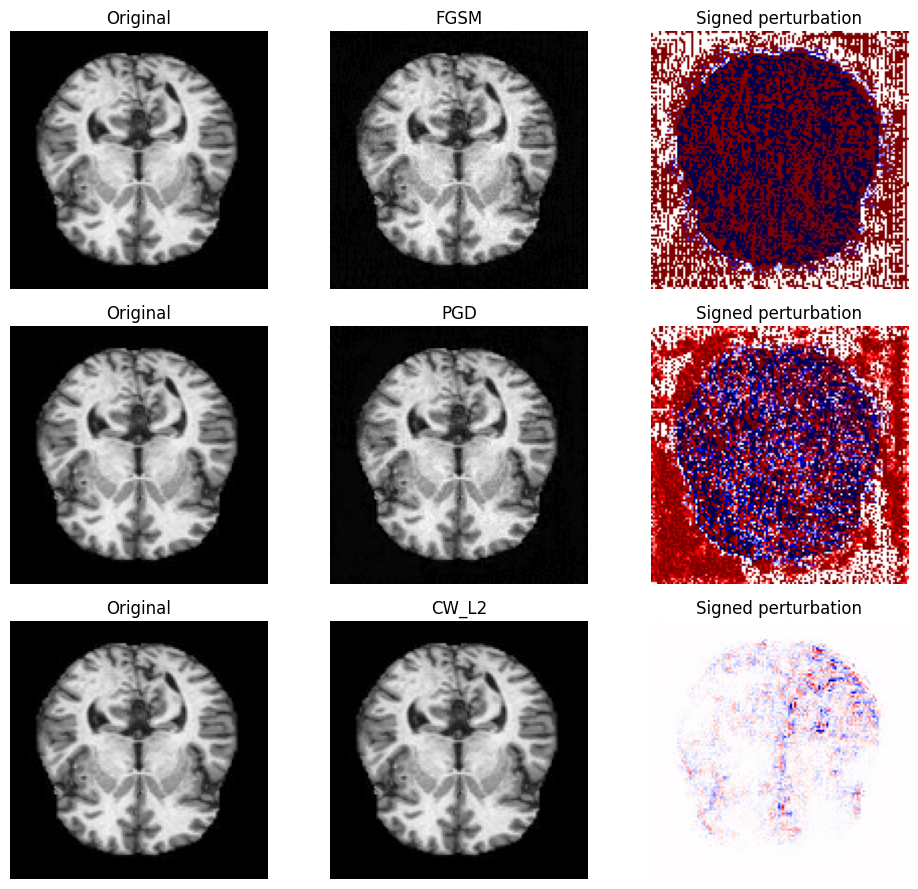

In [14]:
fig,axes=plt.subplots(3,3,figsize=(10,9))
for r,attack in enumerate(["FGSM","PGD","CW_L2"]):
    with np.load(OUT/f"test_{attack}_correct_only.npz",allow_pickle=False) as z:
        orig=z["original_images"][0,0]
        adv=z["adversarial_images"][0,0]
    diff=adv-orig
    axes[r,0].imshow(orig,cmap="gray",vmin=0,vmax=1); axes[r,0].set_title("Original")
    axes[r,1].imshow(adv,cmap="gray",vmin=0,vmax=1); axes[r,1].set_title(attack)
    vmax=max(float(np.max(np.abs(diff))),1e-8)
    axes[r,2].imshow(diff,cmap="seismic",vmin=-vmax,vmax=vmax); axes[r,2].set_title("Signed perturbation")
    for ax in axes[r]: ax.axis("off")
plt.tight_layout(); plt.show()

## Step 14 – Save configuration and package final outputs

In [15]:
config={
    "stage":7,
    "version":"final_corrected",
    "attack_evaluation_protocol":"attacks generated only for samples correctly classified by the clean Stage 4 CNN",
    "attack_success_definition":"adversarial prediction differs from the true label among clean-correct samples",
    "classifier":"fixed Stage 4 four-block CNN",
    "splits":"original Stage 3/4 image-level train/validation/test indices",
    "attacks":ATTACKS,
    "cw_objective":"untargeted tanh-space L2 objective: squared L2 distance plus constant times positive classification margin",
    "cw_success_rule":"only originally correctly classified samples are attacked; unsuccessful optimization cases remain failures",
    "image_shape":[1,128,128],"image_range":[0.0,1.0],
    "seed":SEED,"device":str(DEVICE),"batch_size":BATCH_SIZE
}
with open(OUT/"stage7_final_config.json","w") as f: json.dump(config,f,indent=2)
zip_path="/content/Stage7_Final_Corrected_Outputs.zip"
with zipfile.ZipFile(zip_path,"w",zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob("*"):
        if p.is_file(): z.write(p,arcname=p.name)
print("Final corrected package:",zip_path)
files.download(zip_path)

Final corrected package: /content/Stage7_Final_Corrected_Outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 15 – Save this final notebook and submit outputs for review

1. Download this notebook and upload it to the private GitHub repository as `Stage7_Final_Corrected_Adversarial_Attacks.ipynb`.
2. Keep the previous Stage 7 notebook and outputs as historical records; do not overwrite them.
3. Upload `Stage7_Final_Corrected_Outputs.zip` here for validation before Stage 8.

The final summary must be based on the outputs actually produced by this notebook. Do not copy previous attack success rates into the final manuscript unless they are reproduced by this corrected run.